# Beamformer
In this notebook we'll use beamforming to do inverse modelling of MEG data. This is an alternative approach to minimum norm estimation, which was introduced in the `source_recon.ipynb`.

However, many of the steps before inverse modelling are similar. We still need to define a the source space (e.g., volumetric or surface) and coregister the MR and the MEG sensors to define the forward model. This is not covered in this notebook, so go back to the other one if you need a reminder! Here we just load a forward model that is already created. 

In [35]:
import mne
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# importing from our local utils
import sys
sys.path.append("../scripts/")

## Preparing the data
Load the epochs from which ICA components associated with eye blinks and cardiac activity have been removed and a bandpass filter has been applied.

In [36]:
# Preparing paths
subject = "0194"

deriv_path = Path(f"/work/data_for_notebooks/{subject}")
subjects_dir = Path("/work/freesurfer")

epochs_ica_path = deriv_path / f"{subject}_filtered_0.1-40_fir_ICA_meg-epo.fif"
fwd_path = deriv_path / f"{subject}_volume-spacing-10mm-fwd.fif"

In [37]:
# loading epochs
epochs_ica = mne.read_epochs(epochs_ica_path)
epochs_ica = epochs_ica["stimulus"]

Reading /work/data_for_notebooks/0194/0194_filtered_0.1-40_fir_ICA_meg-epo.fif ...
    Read a total of 9 projection items:
        planar-Raw-0.000-120.000-PCA-01 (1 x 203) active
        planar-Raw-0.000-120.000-PCA-02 (1 x 203) active
        planar-Raw-0.000-120.000-PCA-03 (1 x 203) active
        axial-Raw-0.000-120.000-PCA-01 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-02 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-03 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-04 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-05 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-06 (1 x 102) active
    Found the data of interest:
        t =    -200.00 ...     696.00 ms
        0 CTF compensation matrices available
Adding metadata with 13 columns
2400 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 9)
9 projection items activated


In [38]:
fwd = mne.read_forward_solution(fwd_path)
noise_cov_ica = mne.compute_covariance(epochs_ica, tmin=None, tmax=0)

Reading forward solution from /work/data_for_notebooks/0194/0194_volume-spacing-10mm-fwd.fif...
    Reading a source space...
    [done]
    1 source spaces read
    Desired named matrix (kind = 3523 (FIFF_MNE_FORWARD_SOLUTION_GRAD)) not available
    Read MEG forward solution (1343 sources, 306 channels, free orientations)
    Source spaces transformed to the forward solution coordinate frame
    Created an SSP operator (subspace dimension = 9)
    Setting small MEG eigenvalues to zero (without PCA)
Reducing data rank from 306 -> 297
Estimating covariance using EMPIRICAL
Done.
Number of samples used : 30600
[done]


One thing that differs between using the beamformer instead of minimum norm estimation is that we also need to compute the data covariance. Spatial filters, like the beamformer, use the data covariance to estimate the filter weights!

    Created an SSP operator (subspace dimension = 9)
    Setting small MEG eigenvalues to zero (without PCA)
Reducing data rank from 306 -> 297
Estimating covariance using EMPIRICAL
Done.
Number of samples used : 105000
[done]
Computing rank from covariance with rank=None
    Using tolerance 1.5e-14 (2.2e-16 eps * 102 dim * 0.65  max singular value)
    Estimated rank (mag): 96
    MAG: rank 96 computed from 102 data channels with 0 projectors
Computing rank from covariance with rank=None
    Using tolerance 4.5e-13 (2.2e-16 eps * 204 dim * 9.9  max singular value)
    Estimated rank (grad): 201
    GRAD: rank 201 computed from 204 data channels with 0 projectors


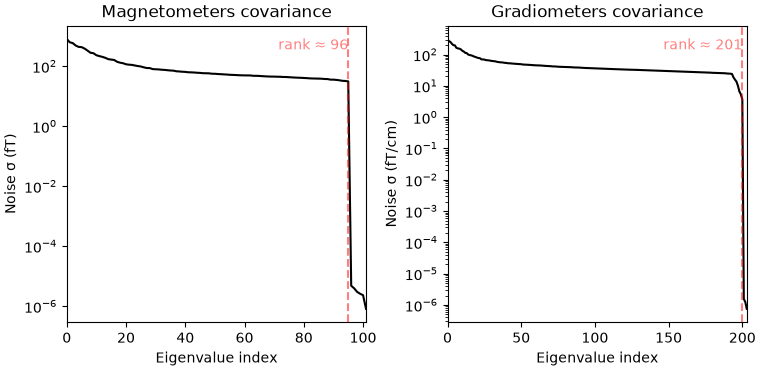

(<Figure size 760x370 with 4 Axes>, <Figure size 760x370 with 2 Axes>)

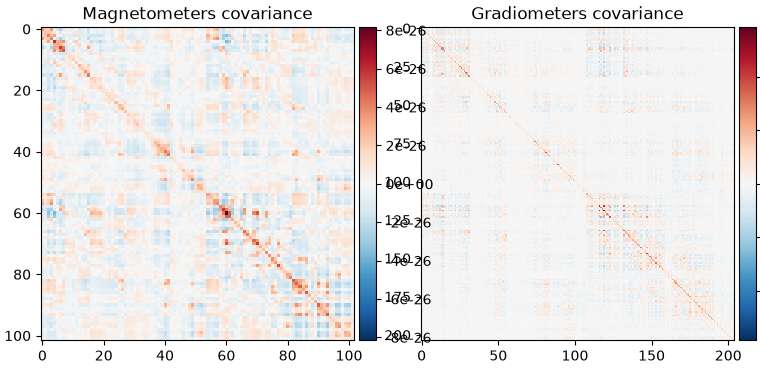

In [39]:
data_cov_ica = mne.compute_covariance(
    epochs_ica, 
    tmin=0,
    tmax=None
)
data_cov_ica.plot(epochs_ica.info)

In [40]:
spatial_filter_ica = mne.beamformer.make_lcmv(
    epochs_ica.info, 
    fwd, 
    data_cov_ica,
    noise_cov=noise_cov_ica
)

Excluding 7 channel(s) missing from the provided forward operator and/or covariance matrices
Computing rank from covariance with rank='info'
    MEG: rank 297 after 9 projectors applied to 306 channels
Computing rank from covariance with rank='info'
    MEG: rank 297 after 9 projectors applied to 306 channels
Making LCMV beamformer with rank {'meg': 297}
Computing inverse operator with 306 channels.
    306 out of 306 channels remain after picking
Selected 306 channels
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 9)
Computing rank from covariance with rank={'meg': 297}
    Setting small MEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing beamformer filters for 1343 sources
Filter computation complete


w(r) = L(r) R⁻¹ / L(r)^T R⁻¹ L(r)

estimate the sources independent for each time-source combination; s(r, t)
applying the estimated weights; w(r)

In [41]:
evoked_ica = epochs_ica.average()
lcmv = mne.beamformer.apply_lcmv(evoked_ica, spatial_filter_ica)

combining the current components...


> ⚠️ **Do not share these plots.**
> The visualisation is overlaid on the participant's MRI, which contains sensitive information. For this reason, the code below is commented out. **Make sure not to accidently share or push to GitHub.**


In [42]:
%matplotlib widget
#lcmv.plot(
#    src=fwd["src"], 
#    subject=subject, 
#    subjects_dir=subjects_dir
#);

# Epochs instead of evoked


In [43]:
lcmvs_ica = mne.beamformer.apply_lcmv_epochs(epochs_ica, spatial_filter_ica)

Processing epoch : 1
combining the current components...
Processing epoch : 2
combining the current components...
Processing epoch : 3
combining the current components...
Processing epoch : 4
combining the current components...
Processing epoch : 5
combining the current components...
Processing epoch : 6
combining the current components...
Processing epoch : 7
combining the current components...
Processing epoch : 8
combining the current components...
Processing epoch : 9
combining the current components...
Processing epoch : 10
combining the current components...
Processing epoch : 11
combining the current components...
Processing epoch : 12
combining the current components...
Processing epoch : 13
combining the current components...
Processing epoch : 14
combining the current components...
Processing epoch : 15
combining the current components...
Processing epoch : 16
combining the current components...
Processing epoch : 17
combining the current components...
Processing epoch : 18
c

# Comparing with minimum norm estimation
Now, lets try to compare the two methods of inverse modelling. First, we make the inverse operator for minimum norm estimation!

In [44]:
inv_ica = mne.minimum_norm.make_inverse_operator(
    epochs_ica.info, 
    fwd,
    noise_cov_ica
)

Computing inverse operator with 306 channels.
    306 out of 306 channels remain after picking
Selected 306 channels
Creating the depth weighting matrix...
    204 planar channels
    limit = 1277/1343 = 10.005518
    scale = 4.91041e-08 exp = 0.8
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 9)
Computing rank from covariance with rank=None
    Using tolerance 6.1e-13 (2.2e-16 eps * 306 dim * 9  max singular value)
    Estimated rank (mag + grad): 297
    MEG: rank 297 computed from 306 data channels with 9 projectors
    Setting small MEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 17.1159
    scaling factor to adjust the trace = 1.84277e+21 (nchan = 306 nzero = 9)


Let's first compare the results for evoked responses!

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 600
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Applying inverse operator to "0.50 × stimulus/gabor/0 + 0.50 × stimulus/gabor/1"...
    Picked 306 channels from the data
    Computing inverse...
    Eigenleads need to be weighted ...
    Computing residual...
    Explained   7.8% variance
    Combining the current components...
[done]
combining the current components...
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (5.0, -89.9, 22.2) mm, [8, 2, 8] vox, 2318 vertex
Using control points [1.04823123e-

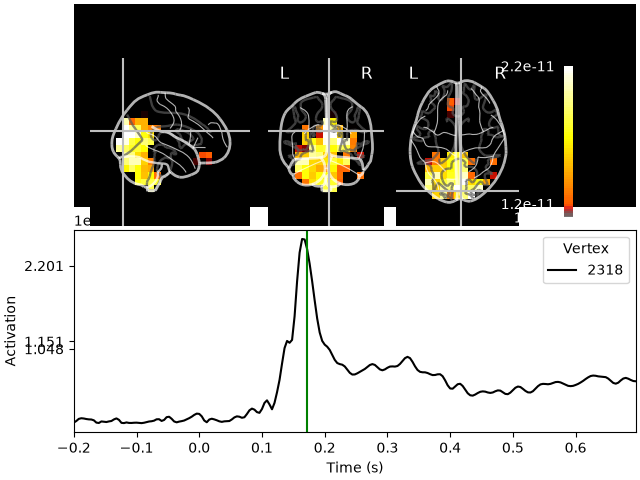

Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (4.6, -93.6, 12.0) mm, [8, 2, 7] vox, 2033 vertex
Using control points [0.34005306 0.38856073 1.14513793]


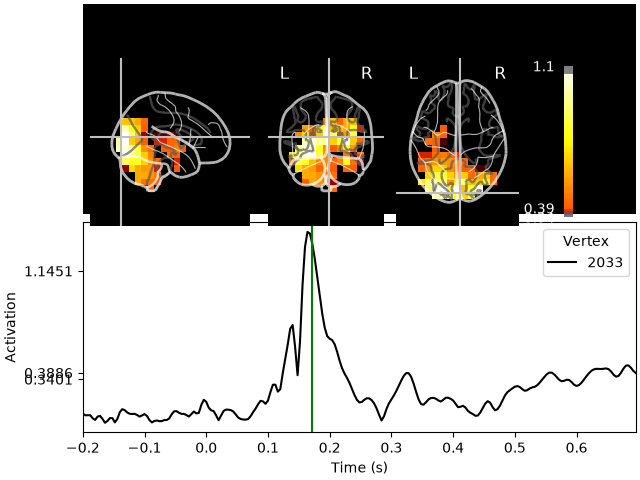

In [45]:
stc_mne = mne.minimum_norm.apply_inverse(
    evoked_ica,
    inv_ica,
    method="MNE"
)

stc_beam = mne.beamformer.apply_lcmv(
            evoked_ica,
            spatial_filter_ica,
        )


for stc_tmp in [stc_mne, stc_beam]:
    stc_tmp.plot(
        src=fwd["src"],
        subjects_dir=subjects_dir,
        initial_time=0.17,
        initial_pos=None,
        mode="glass_brain",
    )

<div class="alert alert-block alert-info">
<b> Question:</b> Click around the interactive plots and compare the two results. In which ways are they the same and in which way do they differ?
</div>

At the trial level, try to compare minimum norm estimation and beamforming! 

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 1
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Picked 306 channels from the data
Computing inverse...
    Eigenleads need to be weighted ...
Processing epoch : 1 / 1
combining the current components...
[done]
Plotting epoch [19], MNE
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (-5.2, 62.5, -16.7) mm, [6, 17, 10] vox, 3111 vertex
Using control points [7.43356235e-11 8.59007008e-11 1.61086196e-10]


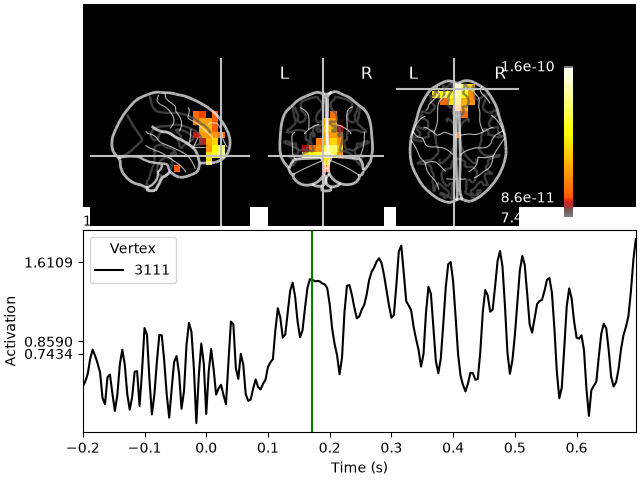

Processing epoch : 1
combining the current components...
[done]
Plotting epoch [19], beamformer
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (-29.5, -92.4, 12.9) mm, [5, 2, 7] vox, 2030 vertex
Using control points [2.92950685 3.10407011 4.20071975]


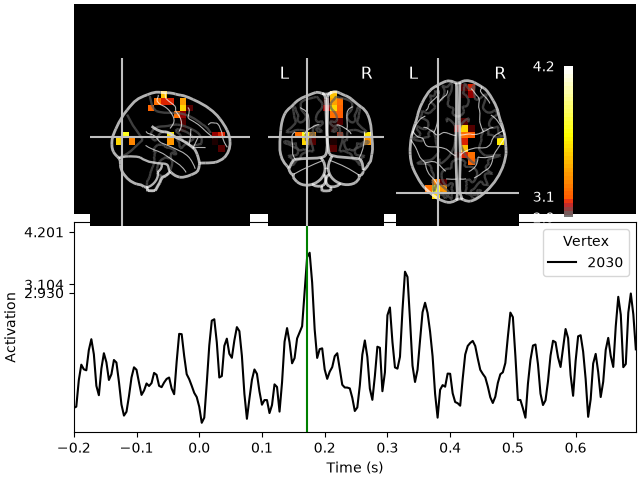

In [46]:
epoch_idx = 19

for label in ["MNE", "beamformer"]:
    epoch_tmp = epochs_ica[epoch_idx]
    inv_tmp = inv_ica
    spatial_filter_tmp = spatial_filter_ica
        
    if label == "MNE":
        stc_tmp = mne.minimum_norm.apply_inverse_epochs(
            epoch_tmp,
            inv_tmp,
            method="MNE",
            lambda2=1.0 / 3**2,
        )

    elif label == "beamformer":
        stc_tmp = mne.beamformer.apply_lcmv_epochs(
            epoch_tmp,
            spatial_filter_tmp,
        )

    print(f"Plotting epoch [{epoch_idx}], {label}")
    stc_tmp[0].plot(
        src=fwd["src"],
        subjects_dir=subjects_dir,
        initial_time=0.17,
        initial_pos=None,
        mode="glass_brain",
    )

<div class="alert alert-block alert-info">
<b> Task:</b> Try plotting different trials and compare the results!
</div>

## The effect of ICA

In [47]:
# also load non-ica'ed epochs 
epochs_path = deriv_path / f"{subject}_filtered_0.1-40_fir_meg-epo.fif"

# loading epochs
epochs = mne.read_epochs(epochs_path)
epochs = epochs["stimulus"]


data_cov = mne.compute_covariance(
    epochs, 
    tmin=0,
    tmax=None
)

noise_cov = mne.compute_covariance(epochs, tmin=None, tmax=0)

inv = mne.minimum_norm.make_inverse_operator(
    epochs.info, 
    fwd,
    noise_cov
)

spatial_filter = mne.beamformer.make_lcmv(
    epochs.info, 
    fwd, 
    data_cov,
    noise_cov=noise_cov
)



Reading /work/data_for_notebooks/0194/0194_filtered_0.1-40_fir_meg-epo.fif ...
    Read a total of 9 projection items:
        planar-Raw-0.000-120.000-PCA-01 (1 x 203) active
        planar-Raw-0.000-120.000-PCA-02 (1 x 203) active
        planar-Raw-0.000-120.000-PCA-03 (1 x 203) active
        axial-Raw-0.000-120.000-PCA-01 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-02 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-03 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-04 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-05 (1 x 102) active
        axial-Raw-0.000-120.000-PCA-06 (1 x 102) active
    Found the data of interest:
        t =    -200.00 ...     696.00 ms
        0 CTF compensation matrices available
Adding metadata with 13 columns
2400 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 9)
9 projection items activated
    Created an SSP operator (subspace dimension = 9)
    Setting small MEG eigenvalues 

### Evoked

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 600
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Applying inverse operator to "0.50 × stimulus/gabor/0 + 0.50 × stimulus/gabor/1"...
    Picked 306 channels from the data
    Computing inverse...
    Eigenleads need to be weighted ...
    Computing residual...
    Explained   7.8% variance
    Combining the current components...
[done]
Plotting evoked, MNE, ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (5.0, -89.9, 22.2) mm, [8, 2, 8] vox, 2318 vertex
Using control points [1.04823123e-11 1.15098

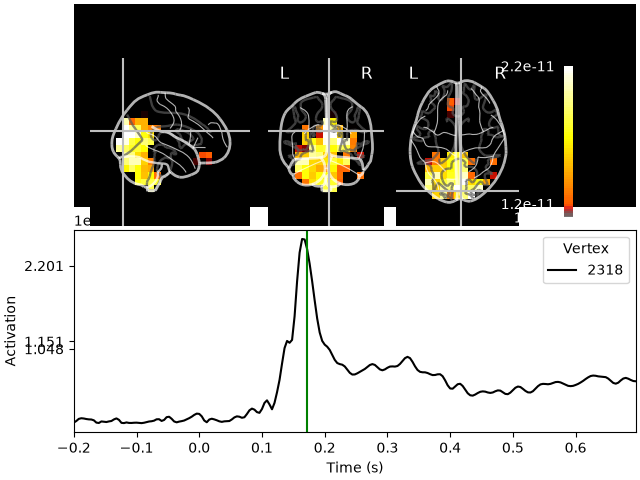

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 600
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Applying inverse operator to "0.50 × stimulus/gabor/0 + 0.50 × stimulus/gabor/1"...
    Picked 306 channels from the data
    Computing inverse...
    Eigenleads need to be weighted ...
    Computing residual...
    Explained  85.2% variance
    Combining the current components...
[done]
Plotting evoked, MNE, no ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (26.9, -98.2, 1.0) mm, [10, 2, 6] vox, 1750 vertex
Using control points [2.75640325e-10 3.1

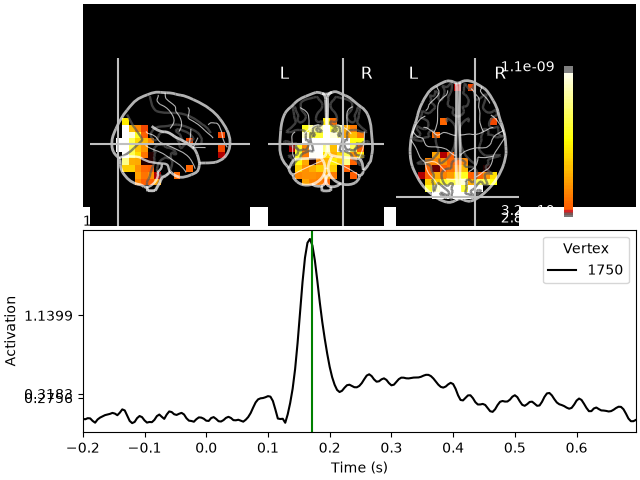

combining the current components...
Plotting evoked, beamformer, ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (4.6, -93.6, 12.0) mm, [8, 2, 7] vox, 2033 vertex
Using control points [0.34005306 0.38856073 1.14513793]


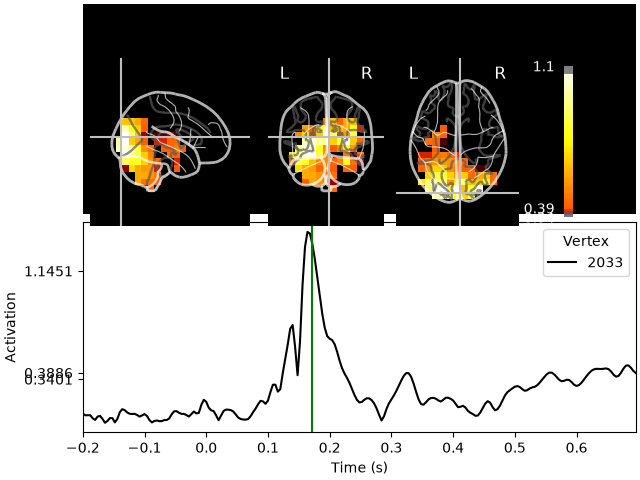

combining the current components...
Plotting evoked, beamformer, no ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (4.5, -91.5, -12.6) mm, [8, 3, 5] vox, 1478 vertex
Using control points [0.43679514 0.50963973 1.42735198]


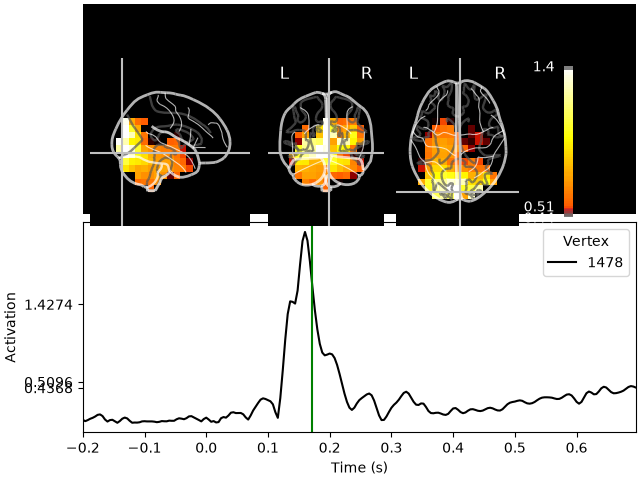

In [48]:
epoch_idx = 19

for label in ["MNE", "beamformer"]:
    for data in ["ica", "no ica"]:
        if data == "ica":
            evoked_tmp = epochs_ica.average()
            inv_tmp = inv_ica
            spatial_filter_tmp = spatial_filter_ica
        else:
            evoked_tmp = epochs.average()
            inv_tmp = inv
            spatial_filter_tmp = spatial_filter

        if label == "MNE":
            stc_tmp = mne.minimum_norm.apply_inverse(
                evoked_tmp,
                inv_tmp,
                method="MNE",
            )

        elif label == "beamformer":
            stc_tmp = mne.beamformer.apply_lcmv(
                evoked_tmp,
                spatial_filter_tmp,
            )

        print(f"Plotting evoked, {label}, {data}")
        stc_tmp.plot(
            src=fwd["src"],
            subjects_dir=subjects_dir,
            initial_time=0.17,
            initial_pos=None,
            mode="glass_brain",
        )


### Single trials

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 1
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Picked 306 channels from the data
Computing inverse...
    Eigenleads need to be weighted ...
Processing epoch : 1 / 1
combining the current components...
[done]
Plotting epoch [19], MNE, ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (-5.2, 62.5, -16.7) mm, [6, 17, 10] vox, 3111 vertex
Using control points [7.43356235e-11 8.59007008e-11 1.61086196e-10]


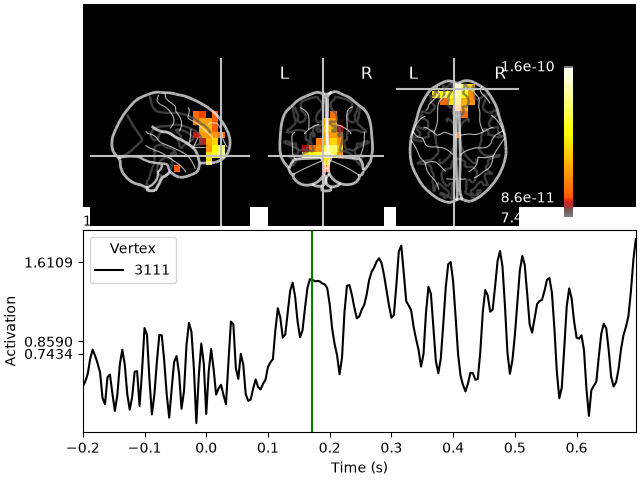

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 1
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 9)
    Created the whitener using a noise covariance matrix with rank 297 (9 small eigenvalues omitted)
Picked 306 channels from the data
Computing inverse...
    Eigenleads need to be weighted ...
Processing epoch : 1 / 1
combining the current components...
[done]
Plotting epoch [19], MNE, no ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (-5.2, 62.5, -16.7) mm, [6, 17, 10] vox, 3111 vertex
Using control points [2.84656728e-09 3.24528856e-09 6.76144394e-09]


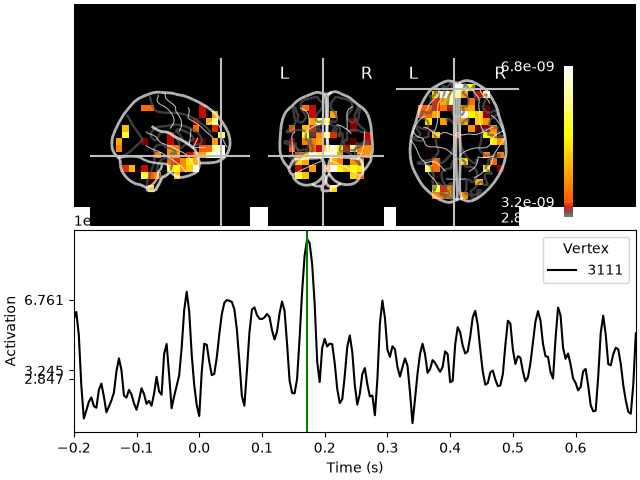

Processing epoch : 1
combining the current components...
[done]
Plotting epoch [19], beamformer, ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (-29.5, -92.4, 12.9) mm, [5, 2, 7] vox, 2030 vertex
Using control points [2.92950685 3.10407011 4.20071975]


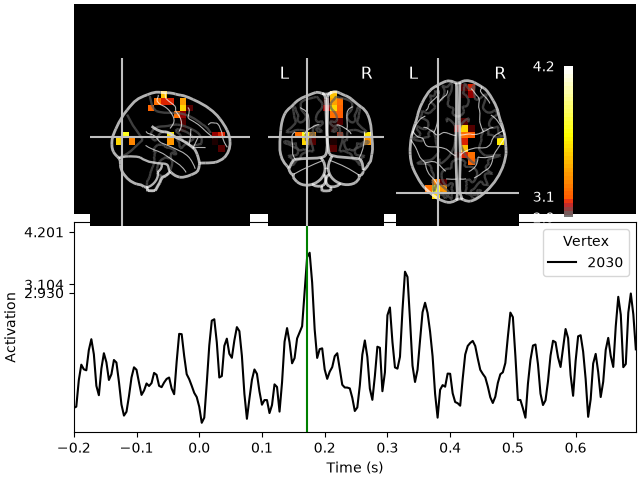

Processing epoch : 1
combining the current components...
[done]
Plotting epoch [19], beamformer, no ica
Transforming subject RAS (non-zero origin) -> MNI Talairach
    1.134740 0.077729 0.043209      -0.13 mm
    -0.041118 0.960349 0.373661      -4.14 mm
    -0.032897 -0.401143 1.027380     -16.60 mm
    0.000000 0.000000 0.000000       1.00

Fixing initial time: 0.17 s
Showing: t = 0.172 s, (65.7, -46.1, 25.1) mm, [13, 6, 10] vox, 2953 vertex
Using control points [3.04317838 3.2373887  4.4532351 ]


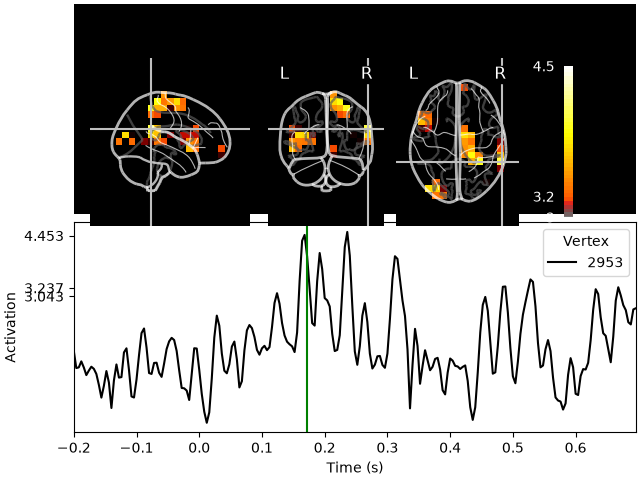

In [49]:
epoch_idx = 19

for label in ["MNE", "beamformer"]:
    for data in ["ica", "no ica"]:
        if data == "ica":
            epoch_tmp = epochs_ica[epoch_idx]
            inv_tmp = inv_ica
            spatial_filter_tmp = spatial_filter_ica
        else:
            epoch_tmp = epochs[epoch_idx]
            inv_tmp = inv
            spatial_filter_tmp = spatial_filter

        if label == "MNE":
            stc_tmp = mne.minimum_norm.apply_inverse_epochs(
                epoch_tmp,
                inv_tmp,
                method="MNE",
                lambda2=1.0 / 3**2,
            )

        elif label == "beamformer":
            stc_tmp = mne.beamformer.apply_lcmv_epochs(
                epoch_tmp,
                spatial_filter_tmp,
            )

        print(f"Plotting epoch [{epoch_idx}], {label}, {data}")
        stc_tmp[0].plot(
            src=fwd["src"],
            subjects_dir=subjects_dir,
            initial_time=0.17,
            initial_pos=None,
            mode="glass_brain",
        )




<div class="alert alert-block alert-info">
<b> Question:</b> Does artefacts influence minimum norm estimation and beamforming differently? 💡 You can also plot the signal in each sensor for the epochs! Maybe you get an idea if there is a non-brain source of signal present before ICA using the code below
</div>

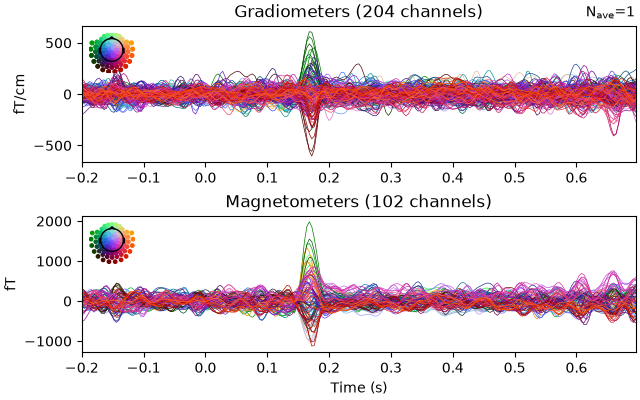

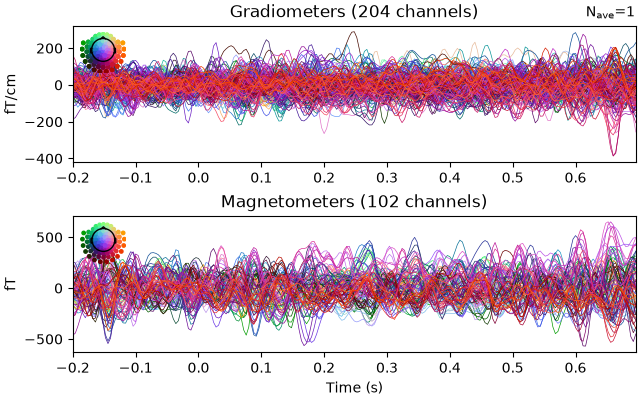

In [50]:
epochs[epoch_idx].average().plot();
epochs_ica[epoch_idx].average().plot();

In [51]:
#epochs.average().plot();